# Estimate a confidence-interval shape from a reported half-life point estimate

This notebook tests simple formulas that take a predicted half-life center `t` and return lower and upper limits. Validation uses 16 published Cavaco peptides and leaves out each peptide in turn; the result applies only to that assay design.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the repository and load the processed TSV data.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "assets/tools/proteolysis_data_manager/src").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
PROCESSED = ROOT / "data/proteolysis/half_time_datasets/processed"
GENERATION_SCRIPT = ROOT / "assets/tools/proteolysis_data_manager/scripts/integration/half_time_data/normalize_datasets.py"
print(f"Generate the TSVs with: {sys.executable} {GENERATION_SCRIPT}")

sequences = pd.read_csv(PROCESSED / "sequences_half_time.tsv", sep="\t", dtype="string",
                        keep_default_na=False, na_values=[""])
experiments = pd.read_csv(
    PROCESSED / "half_time_experiments.tsv", sep="\t",
    dtype={"experiment_id": "string", "sequence_id": "string", "source_record_id": "string",
           "publication_id": "string"},
    keep_default_na=False, na_values=[""],
)
from proteolysis_data_manager.analysis.half_life.intervals import (
    FAMILIES, reported_intervals, validate_interval_estimator,
)
from proteolysis_data_manager.analysis.half_life.visualization import plot_reported_intervals

intervals = reported_intervals(experiments, sequences)
print(f"Usable records: {len(intervals)}; source: {', '.join(sorted(intervals.source.unique()))}.")

Generate the TSVs with: /home/max/repositories/pep-compass/.venv/bin/python /home/max/repositories/pep-compass/assets/tools/proteolysis_data_manager/scripts/integration/half_time_data/normalize_datasets.py
Usable records: 16; source: cavaco.


**Reference data.** Cavaco et al. report half-life point estimates and 95% CIs for the mean of three experiments in 50% human serum at 37°C and 500 µM peptide. We have 16 intervals, but no raw replicates. We can test whether a formula reproduces the published endpoints; we cannot independently validate 95% coverage. [Cavaco et al., 2021](https://doi.org/10.1111/cts.12985).

,Peptide ID,Sequence,Point t (s),CI lower (s),CI upper (s),CI level,n,Peptide (µM)
0,15,GAARYAGWGAYRAAG,3300.00,2580.00,4200.00,0.95,3.00,500.00
1,12,GSSRSYGSGYSRSSG,1740.00,1200.00,2460.00,0.95,3.00,500.00
2,6,GSSRSSGSGSSRSSG,480.00,360.00,660.00,0.95,3.00,500.00
3,11,GAAQAYGWGYAQAAG,17340.00,7620.00,56460.00,0.95,3.00,500.00
4,3,GAARAAGSGAARAAG,5220.00,4320.00,6420.00,0.95,3.00,500.00
5,2,GSSQSSGSGSSQSSG,1980.00,1560.00,2460.00,0.95,3.00,500.00
6,5,GAAQAAGWGAAQAAG,4020.00,2640.00,6300.00,0.95,3.00,500.00
7,7,GSSQSYGSGYSQSSG,2880.00,2100.00,3900.00,0.95,3.00,500.00
8,1,GAAQAAGSGAAQAAG,2880.00,1680.00,4680.00,0.95,3.00,500.00
9,14,GSSQYAGWGAYQSSG,2460.00,1500.00,3840.00,0.95,3.00,500.00


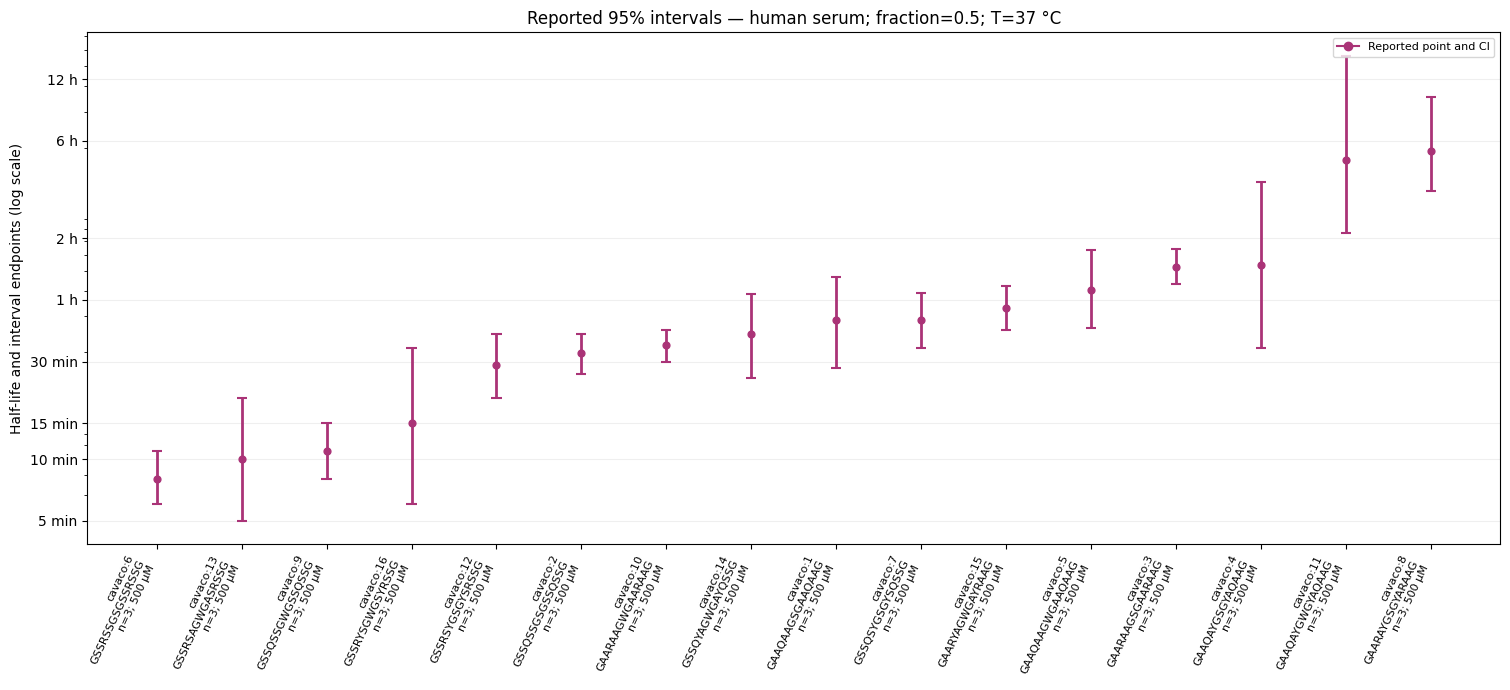

In [2]:
TIME_SCALE = "log"  # "log" or "linear"
display(intervals[["source_record_id", "sequence", "half_life_seconds", "ci_lower_seconds", "ci_upper_seconds",
                   "ci_level", "replicate_count", "peptide_concentration_um"]]
        .rename(columns={"source_record_id": "Peptide ID", "sequence": "Sequence", "half_life_seconds": "Point t (s)",
                         "ci_lower_seconds": "CI lower (s)", "ci_upper_seconds": "CI upper (s)", "ci_level": "CI level",
                         "replicate_count": "n", "peptide_concentration_um": "Peptide (µM)"})
        .style.format(precision=2).set_caption("Reported point estimates and CI endpoints"))
fig = plot_reported_intervals(intervals, scale=TIME_SCALE)
display(fig)
plt.close(fig)

## Method 1 — Linear relative-width estimator

For a point estimate `t`, estimate positive log-relative distances to the two reported bounds:

\[
 d_L(t)=\log\!\left(\frac{t}{L(t)}\right),\qquad
 d_U(t)=\log\!\left(\frac{U(t)}{t}\right).
\]

Fit each distance as a linear function of normalized half-life, `d(t) = a + b·(t/t₀)`, where `t₀` is the geometric mean of training half-lives. The deterministic output is `L̂(t) = t·exp(−d̂_L(t))` and `Û(t) = t·exp(d̂_U(t))`; positive distances ensure `L̂(t) < t < Û(t)`. Coefficients minimize the training loss `J = (1/(2N))·Σᵢ[(ln(L̂ᵢ/Lᵢ))² + (ln(Ûᵢ/Uᵢ))²]`.

The code leaves out one peptide identity at a time, fits on the other peptides, then compares predicted `L̂, Û` with Cavaco's reported `L, U`. Fitting minimizes `J` on training peptides. The held-out table reports `J`, the mean absolute log-endpoint error `E_abs` and its multiplicative factor `exp(E_abs)`, plus separate median relative errors for the lower and upper bounds. A factor of 1 is exact. The plot pairs each peptide's reported interval with its leave-one-peptide-out prediction; the point estimate `t` is marked in both.


,Estimator,Held-out peptides,Mean squared log endpoint error,Mean abs. log endpoint error,Endpoint error factor,Median lower error (%),Median upper error (%)
0,Linear relative width,16,0.088,0.241,1.273,19.5,25.1


Reference t₀: 42.5 min; full-data domain: 8.0–322.0 min
Coefficients [intercept, slope] for [lower, upper] widths:
[[0.41486159 0.36755838]
 [0.02818308 0.06726648]]


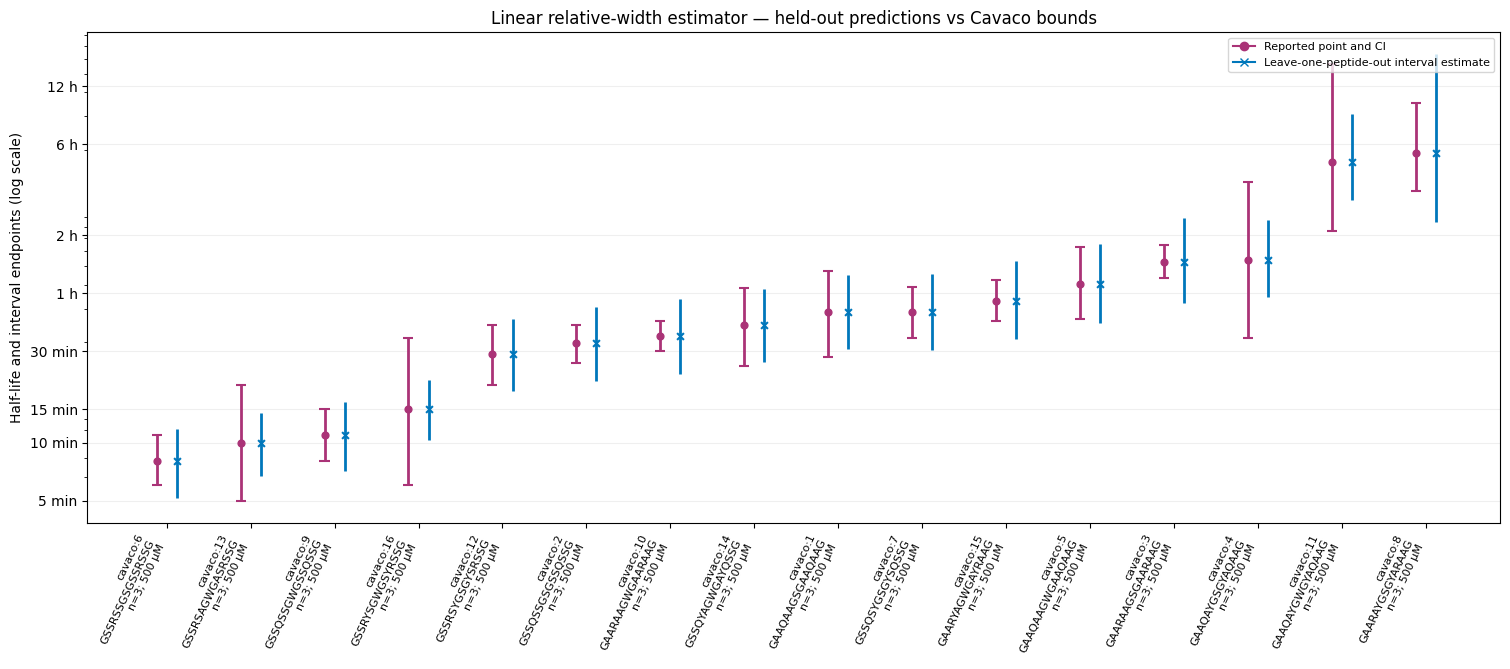

In [3]:
metric, held_out, model = validate_interval_estimator(intervals, family="linear")

metric_display = metric.rename(columns={
    "family": "Estimator", "held_out_peptides": "Held-out peptides",
    "mean_squared_log_endpoint_error": "Mean squared log endpoint error",
    "mean_absolute_log_endpoint_error": "Mean abs. log endpoint error",
    "multiplicative_error_factor": "Endpoint error factor",
    "median_absolute_lower_relative_error": "Median lower error (%)",
    "median_absolute_upper_relative_error": "Median upper error (%)",
})
metric_display["Estimator"] = "Linear relative width"
metric_display["Median lower error (%)"] *= 100
metric_display["Median upper error (%)"] *= 100
display(metric_display[["Estimator", "Held-out peptides", "Mean squared log endpoint error",
                        "Mean abs. log endpoint error",
                        "Endpoint error factor", "Median lower error (%)", "Median upper error (%)"]]
        .style.format({"Mean squared log endpoint error": "{:.3f}",
                       "Mean abs. log endpoint error": "{:.3f}", "Endpoint error factor": "{:.3f}",
                       "Median lower error (%)": "{:.1f}",
                       "Median upper error (%)": "{:.1f}"})
        .set_caption("Linear estimator — leave-one-peptide-out endpoint errors"))

coefficients = np.asarray(model.coefficients)
print(f"Reference t₀: {model.reference_seconds / 60:.1f} min; full-data domain: {model.domain_seconds[0] / 60:.1f}–{model.domain_seconds[1] / 60:.1f} min")
print("Coefficients [intercept, slope] for [lower, upper] widths:")
print(coefficients)

fig = plot_reported_intervals(held_out, estimates=True, scale="log")
fig.axes[0].set_title("Linear relative-width estimator — held-out predictions vs Cavaco bounds")
display(fig)
plt.close(fig)

## Method 2 — Logarithmic relative-width estimator

Use the same positive log-relative distances `d_L(t) = log(t/L)` and `d_U(t) = log(U/t)`, but model each as `d(t) = a + b·log(t/t₀)`, with `t₀` the geometric mean of training half-lives. This gives the deterministic bounds `L̂(t) = t·exp(−d̂_L(t))` and `Û(t) = t·exp(d̂_U(t))`; the fitted distances must stay positive over the prediction domain.

The coefficients minimize the same training loss `J` defined in Method 1. The code uses the same peptide-wise holdout and held-out endpoint metrics, so scores are directly comparable. Its plot shows the predicted and reported lower/upper bounds for each held-out Cavaco peptide, together with the input point estimate `t`.


,Estimator,Held-out peptides,Mean squared log endpoint error,Mean abs. log endpoint error,Endpoint error factor,Median lower error (%),Median upper error (%)
0,Logarithmic relative width,16,0.089,0.239,1.270,17.9,26.4


Reference t₀: 42.5 min; full-data domain: 8.0–322.0 min
Coefficients [intercept, slope] for [lower, upper] widths:
[[0.46407832 0.48502729]
 [0.03279802 0.09393112]]


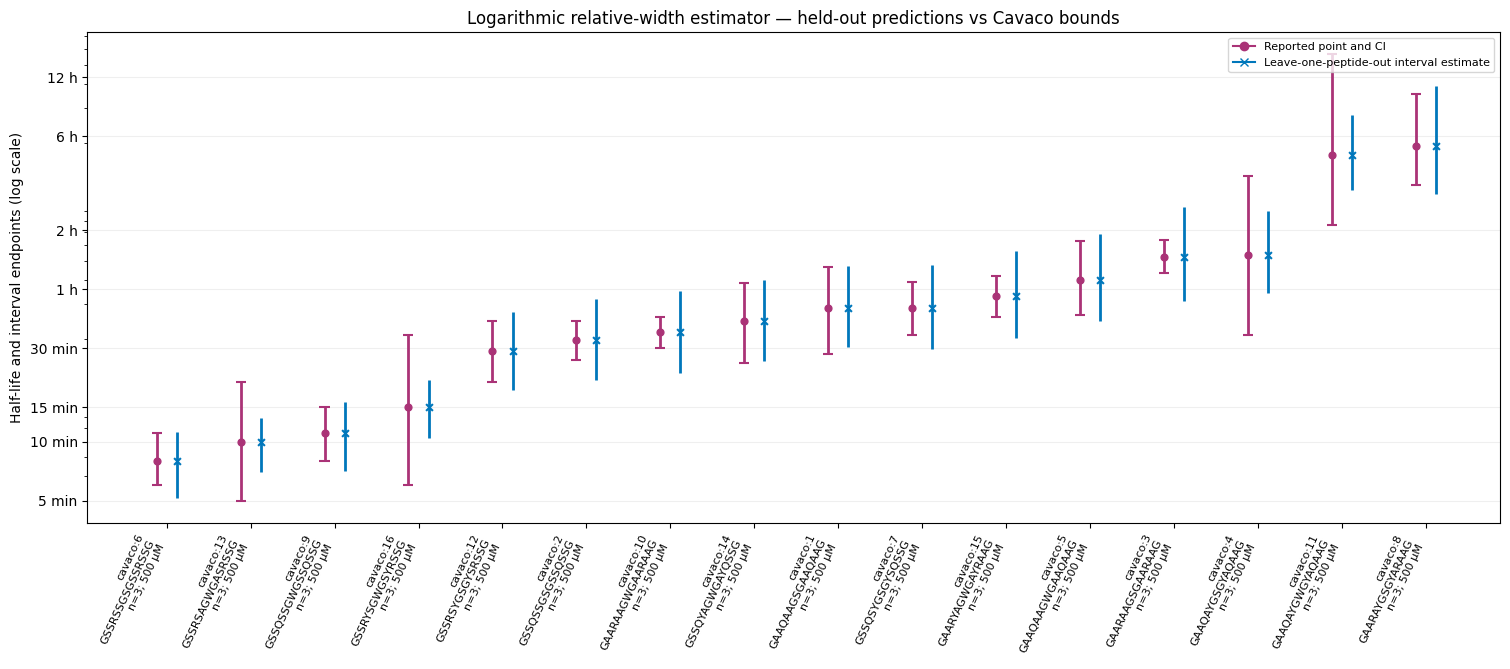

In [4]:
metric, held_out, model = validate_interval_estimator(intervals, family="logarithmic")

metric_display = metric.rename(columns={
    "family": "Estimator", "held_out_peptides": "Held-out peptides",
    "mean_squared_log_endpoint_error": "Mean squared log endpoint error",
    "mean_absolute_log_endpoint_error": "Mean abs. log endpoint error",
    "multiplicative_error_factor": "Endpoint error factor",
    "median_absolute_lower_relative_error": "Median lower error (%)",
    "median_absolute_upper_relative_error": "Median upper error (%)",
})
metric_display["Estimator"] = "Logarithmic relative width"
metric_display["Median lower error (%)"] *= 100
metric_display["Median upper error (%)"] *= 100
display(metric_display[["Estimator", "Held-out peptides", "Mean squared log endpoint error",
                        "Mean abs. log endpoint error",
                        "Endpoint error factor", "Median lower error (%)", "Median upper error (%)"]]
        .style.format({"Mean squared log endpoint error": "{:.3f}",
                       "Mean abs. log endpoint error": "{:.3f}", "Endpoint error factor": "{:.3f}",
                       "Median lower error (%)": "{:.1f}",
                       "Median upper error (%)": "{:.1f}"})
        .set_caption("Logarithmic estimator — leave-one-peptide-out endpoint errors"))

coefficients = np.asarray(model.coefficients)
print(f"Reference t₀: {model.reference_seconds / 60:.1f} min; full-data domain: {model.domain_seconds[0] / 60:.1f}–{model.domain_seconds[1] / 60:.1f} min")
print("Coefficients [intercept, slope] for [lower, upper] widths:")
print(coefficients)

fig = plot_reported_intervals(held_out, estimates=True, scale="log")
fig.axes[0].set_title("Logarithmic relative-width estimator — held-out predictions vs Cavaco bounds")
display(fig)
plt.close(fig)

## Method 3 — Exponential relative-width estimator

Model the positive log-relative distances as `d_L(t) = exp(a_L + b_L·t/t₀)` and `d_U(t) = exp(a_U + b_U·t/t₀)`. The deterministic bounds remain `L̂(t) = t·exp(−d_L(t))` and `Û(t) = t·exp(d_U(t))`, so the point estimate is always enclosed when the calculation is finite. Parameters minimize the same training loss `J` defined in Method 1.

The code again holds out one peptide at a time, minimizes `J`, reports the same held-out endpoint metrics, and plots each leave-one-peptide-out interval prediction beside the published Cavaco interval. Comparing the three metric rows shows which simple dependence predicts the reported bounds with the smallest held-out error.


,Estimator,Held-out peptides,Mean squared log endpoint error,Mean abs. log endpoint error,Endpoint error factor,Median lower error (%),Median upper error (%)
0,Exponential relative width,16,0.095,0.247,1.280,19.5,24.8


Reference t₀: 42.5 min; full-data domain: 8.0–322.0 min
Coefficients [intercept, slope] for [lower, upper] widths:
[[-0.86929433 -0.94537456]
 [ 0.05407417  0.10928504]]


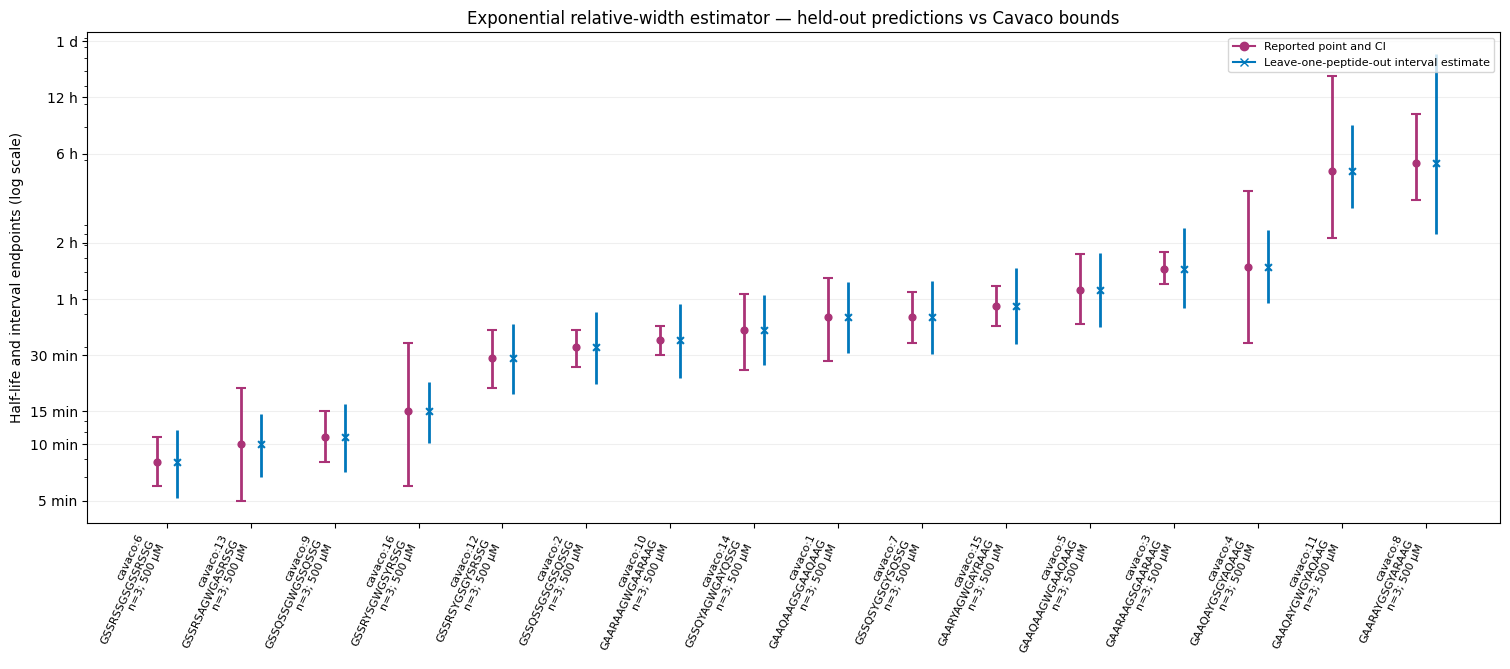

In [5]:
metric, held_out, model = validate_interval_estimator(intervals, family="exponential")

metric_display = metric.rename(columns={
    "family": "Estimator", "held_out_peptides": "Held-out peptides",
    "mean_squared_log_endpoint_error": "Mean squared log endpoint error",
    "mean_absolute_log_endpoint_error": "Mean abs. log endpoint error",
    "multiplicative_error_factor": "Endpoint error factor",
    "median_absolute_lower_relative_error": "Median lower error (%)",
    "median_absolute_upper_relative_error": "Median upper error (%)",
})
metric_display["Estimator"] = "Exponential relative width"
metric_display["Median lower error (%)"] *= 100
metric_display["Median upper error (%)"] *= 100
display(metric_display[["Estimator", "Held-out peptides", "Mean squared log endpoint error",
                        "Mean abs. log endpoint error",
                        "Endpoint error factor", "Median lower error (%)", "Median upper error (%)"]]
        .style.format({"Mean squared log endpoint error": "{:.3f}",
                       "Mean abs. log endpoint error": "{:.3f}", "Endpoint error factor": "{:.3f}",
                       "Median lower error (%)": "{:.1f}",
                       "Median upper error (%)": "{:.1f}"})
        .set_caption("Exponential estimator — leave-one-peptide-out endpoint errors"))

coefficients = np.asarray(model.coefficients)
print(f"Reference t₀: {model.reference_seconds / 60:.1f} min; full-data domain: {model.domain_seconds[0] / 60:.1f}–{model.domain_seconds[1] / 60:.1f} min")
print("Coefficients [intercept, slope] for [lower, upper] widths:")
print(coefficients)

fig = plot_reported_intervals(held_out, estimates=True, scale="log")
fig.axes[0].set_title("Exponential relative-width estimator — held-out predictions vs Cavaco bounds")
display(fig)
plt.close(fig)